# QSVM (Quantum SVM) avec PennyLane — pipeline essentiel

Version minimale, juste pour comprendre le mécanisme de base avant d'ajouter quoi que ce soit d'autre.

Étapes : charger les données → split train/test → standardiser → réduire à `n_qubits` dimensions (PCA) →
mettre à l'échelle en angles → calculer le noyau quantique → entraîner un `SVC(kernel="precomputed")` →
une seule métrique (ROC-AUC) pour vérifier que ça marche.

In [1]:
!pip install pennylane pennylane-lightning scikit-learn pandas openpyxl

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import pandas as pd

file_path = "/content/drive/MyDrive/GBM_GSM_Project/gsm_gbm_12features.xlsx"
df = pd.read_excel(file_path)

X = df.drop(columns=["Y"])
y = df["Y"]

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

#146 patients pour entrainement et 37 pour évaluation

In [5]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import numpy as np
from imblearn.over_sampling import SMOTE

n_qubits = 12  # nombre de qubits = nombre de features utilisées par le circuit

# Standardisation (fit sur train uniquement)
# pour mettre toutes les variables sur une échelle commune
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# SMOTE : rééquilibrage des classes sur le train uniquement
print("Avant SMOTE:", y_train.value_counts().to_dict())

smote = SMOTE(random_state=42)
X_train_scaled, y_train_smote = smote.fit_resample(X_train_scaled, y_train)
y_train_smote = y_train_smote.reset_index(drop=True)
# X_test et y_test restent COMPLÈTEMENT inchangés, jamais touchés par SMOTE

print("Après SMOTE:", y_train_smote.value_counts().to_dict())
print("X_train_scaled shape:", X_train_scaled.shape)
print("y_train_smote shape:", y_train_smote.shape)

# Apprend le min et le max de chaque feature standardisée sur le TRAIN (post-SMOTE) uniquement,
# puis convertit ces valeurs dans l'intervalle [0, pi] (angles de rotation)
angle_scaler = MinMaxScaler(feature_range=(0, np.pi))
X_train_q = angle_scaler.fit_transform(X_train_scaled)

# Meme chose pour le test, mais sans réapprendre pour éviter la fuite de données
X_test_q = angle_scaler.transform(X_test_scaled)

print("X_train_q shape:", X_train_q.shape)
print("X_test_q shape:", X_test_q.shape)

Avant SMOTE: {0: 80, 1: 66}
Après SMOTE: {0: 80, 1: 80}
X_train_scaled shape: (160, 12)
y_train_smote shape: (160,)
X_train_q shape: (160, 12)
X_test_q shape: (37, 12)


In [6]:
import pennylane as qml


#Creation d'un simulateur quantique avec 12 qubits
dev = qml.device("default.qubit", wires=n_qubits)

#fonction pour comment encoder un patient dans le circuit 
def feature_map(x):
    # Prend les 12 valeurs d'un patient 'x' et les transforme en état quantique
    #chaque valeur devient un angle de rotation appliqué à un qubit
    qml.AngleEmbedding(x, wires=range(n_qubits), rotation="Y")
    # intrication entre qubits pour rendre l'encodage plus expressif
    # les qubits deviennent dépendants les uns des autres en ajoutant des portes CNOT
    for i in range(n_qubits):
        qml.CNOT(wires=[i, (i + 1) % n_qubits])

@qml.qnode(dev) # transforme la fonction ci-dessous en un véritables circuit quantique
def kernel_circuit(x1, x2):

    #Etape1: encode le patient x1 dans les qubits
    feature_map(x1)

    #Applique l'inverse de l'encodage du patient x2

    # si x1 et x2 sont très similaires, encoder x1 puis "défaire"
    # l'encodage de x2 devrait ramener les qubits proche de l'état de départ
    # |00...0>. Si x1 et x2 sont très différents, ce ne sera pas le cas.

    qml.adjoint(feature_map)(x2)

    #calculer la probabilité de chaque résultat possible, 2^n qubits resultats
    return qml.probs(wires=range(n_qubits))


def quantum_kernel(x1, x2):
    # similarité entre x1 et x2 = probabilité de revenir à l'état |00...0>
    #si cette probabilité est très haute, doncb les patients se ressemblent
    #si elle est très basse, donc les patients sont différents
    return kernel_circuit(x1, x2)[0]

In [7]:
#calcule matrice de similarité dont le svm a besoin

#Pour apprendre, compare chque patient d'entrainement avec chaque autre patient d'entrainement
K_train = qml.kernels.kernel_matrix(X_train_q, X_train_q, quantum_kernel)

#Compare chaque patient de test avec chaque patient d'entrainement
#le SVM a besoin de savoir "à quel point ce patient de test ressemble à chacun 
#des patients d'entraînement qu'il a utilisés pour construire sa frontière de décision"
# 37*146
K_test = qml.kernels.kernel_matrix(X_test_q, X_train_q, quantum_kernel)

In [8]:
print("X_train_q shape:", X_train_q.shape)   
print("K_train shape:", K_train.shape)       
print("y_train_smote shape:", y_train_smote.shape) 

X_train_q shape: (160, 12)
K_train shape: (160, 160)
y_train_smote shape: (160,)


Heatmap:
On trie les patients par classe (GBM puis GSM) avant d'afficher la matrice, pour voir si le noyau quantique
sépare bien les deux groupes. Si K_train forme bien 2 blocs clairs distincts (haute similarité intra-classe)
séparés par des zones sombres (faible similarité inter-classe), c'est un bon signe que le noyau capture une
vraie structure. Si tout est mélangé sans motif clair, le noyau ne distingue pas bien GBM de GSM.

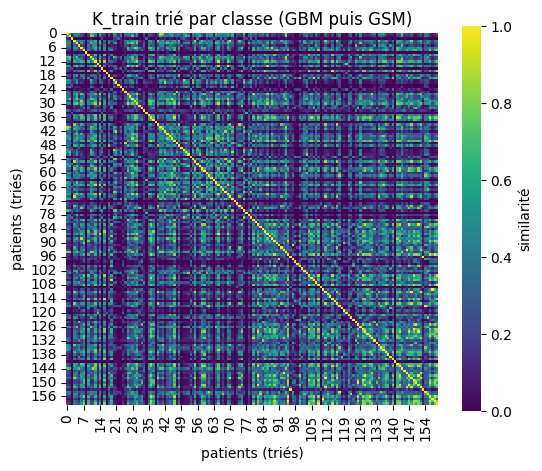

In [9]:
#Visualiser k_train (heatmap)

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


# Ordonne les indices des patients d'entraînement par classe (toutes les
# valeurs de la classe 0 d'abord, puis toutes celles de la classe 1)
order = np.argsort(y_train_smote.values)
k_train_sorted = K_train[order][:, order]


plt.figure(figsize=(6, 5))
sns.heatmap(k_train_sorted, cmap="viridis", square=True, cbar_kws={"label": "similarité"})
plt.title("K_train trié par classe (GBM puis GSM)")
plt.xlabel("patients (triés)")
plt.ylabel("patients (triés)")
plt.show()

In [17]:
# Recalcule les données SANS SMOTE, à partir de X_train original (jamais modifié)
# en réutilisant les transformations déjà apprises (scaler, angle_scaler)
X_train_scaled_orig = scaler.transform(X_train)
X_train_q_orig = angle_scaler.transform(X_train_scaled_orig)

# Recalcule le noyau quantique sur ces 146 patients originaux uniquement
K_train_orig = qml.kernels.kernel_matrix(X_train_q_orig, X_train_q_orig, quantum_kernel)

print("K_train_orig shape:", K_train_orig.shape)  # devrait être (146, 146)
print("y_train shape:", y_train.shape)             # devrait être (146,) -- le y_train ORIGINAL, pas y_train_smote

K_train_orig shape: (146, 146)
y_train shape: (146,)


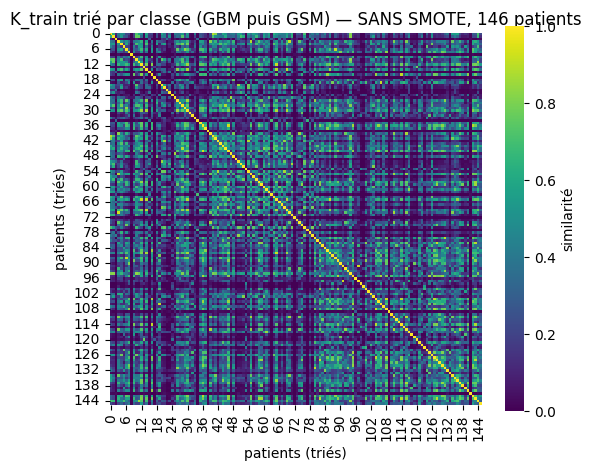

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Ordonne par classe, en utilisant y_train ORIGINAL (146 patients, pas y_train_smote)
order = np.argsort(y_train.values)
k_train_sorted_orig = K_train_orig[order][:, order]

plt.figure(figsize=(6, 5))
sns.heatmap(k_train_sorted_orig, cmap="viridis", square=True, cbar_kws={"label": "similarité"})
plt.title("K_train trié par classe (GBM puis GSM) — SANS SMOTE, 146 patients")
plt.xlabel("patients (triés)")
plt.ylabel("patients (triés)")
plt.show()

In [10]:
from sklearn.svm import SVC

#creation du SVM
#precomputed signifie que je donne directement la matrice de similarités déjà calculée
qsvm = SVC(kernel="precomputed", probability=True, C=1.0, random_state=42)

#entraine le svm avec k_train (similarité train-train, 146*146) au lien des features brutes
qsvm.fit(K_train, y_train_smote)

#Predit sur les patients de test avec k-test
#predict proba retourne 2 colonnes [proba classe 0, proba class 1]
#garde seulement la probabilité de la classe positive, pour calculer le ROC_AUC
y_prob_q = qsvm.predict_proba(K_test)[:, 1]

In [11]:
from sklearn.metrics import roc_auc_score

# Compare les vraies étiquettes (y_test) aux probabilités prédites (y_prob_q)
# pour calculer le ROC-AUC : une mesure de 0 à 1 de la capacité du modèle
# à distinguer les deux classes (GBM vs GSM), peu importe le seuil de décision.
# 0.5 = pas mieux que le hasard, 1.0 = séparation parfaite.
auc_q = roc_auc_score(y_test, y_prob_q)
print(f"ROC-AUC: {auc_q:.3f}")

ROC-AUC: 0.921


Validation croisee

Je prends tes données d'entraînement (disons 160 patients) et tu les découpes en 5 groupes égaux (32 patients chacun).
je fais 5 tours :
Tour 1 : groupes 2,3,4,5 servent à entraîner → groupe 1 sert à tester.
Tour 2 : groupes 1,3,4,5 servent à entraîner → groupe 2 sert à tester.
Tour 3 : groupes 1,2,4,5 servent à entraîner → groupe 3 sert à tester.
... et ainsi de suite, jusqu'à ce que chaque groupe ait servi une fois de "test".
j' obtiens 5 résultats (5 AUC par exemple), que tu moyennes.

La validation croisée évite d'évaluer votre modèle sur un simple coup de chance ou de malchance lié au découpage des données.

In [12]:
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score
import numpy as np

# On réutilise K_train déjà calculé — aucun nouveau circuit quantique n'est simulé ici,
# on ne fait que découper la matrice de similarité en sous-blocs par fold.

y_arr = y_train_smote.values if hasattr(y_train_smote, "values") else np.array(y_train_smote)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

C_values = [0.1, 1, 10, 100] # *10
results = {}

for C in C_values:
    fold_aucs = []
    for train_idx, val_idx in cv.split(K_train, y_arr): #training and validation indexes
        # Pour un kernel précalculé, il faut découper LIGNES ET COLONNES
        # selon les mêmes indices train_idx pour l'entraînement du fold

        #ça extrait les lignes et les colonnes des patients dont on veut la similarité, entre eux uniquement
        K_fold_train = K_train[np.ix_(train_idx, train_idx)] 

        # et lignes = validation, colonnes = train pour la prédiction
        #Içi on trouve à quel point chaque patient de validation resemble à chacun des patients d'entrainements
        K_fold_val = K_train[np.ix_(val_idx, train_idx)]

        y_fold_train, y_fold_val = y_arr[train_idx], y_arr[val_idx]

        model = SVC(kernel="precomputed", C=C, probability=True, random_state=42)
        model.fit(K_fold_train, y_fold_train)

        y_prob = model.predict_proba(K_fold_val)[:, 1]
        fold_aucs.append(roc_auc_score(y_fold_val, y_prob))

    results[C] = (np.mean(fold_aucs), np.std(fold_aucs))
    print(f"C={C}: AUC moyenne={np.mean(fold_aucs):.3f}, écart-type={np.std(fold_aucs):.3f}")

best_C = max(results, key=lambda c: results[c][0])
print("\nMeilleur C:", best_C, "→ AUC CV:", f"{results[best_C][0]:.3f} ± {results[best_C][1]:.3f}")

C=0.1: AUC moyenne=0.821, écart-type=0.062
C=1: AUC moyenne=0.862, écart-type=0.059
C=10: AUC moyenne=0.825, écart-type=0.049
C=100: AUC moyenne=0.742, écart-type=0.085

Meilleur C: 1 → AUC CV: 0.862 ± 0.059


In [16]:
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score

qsvm_final = SVC(kernel="precomputed", C=best_C, probability=True, random_state=42)
qsvm_final.fit(K_train, y_train_smote)

y_pred_q_final = qsvm_final.predict(K_test)
y_prob_q_final = qsvm_final.predict_proba(K_test)[:, 1]

accuracy_q = accuracy_score(y_test, y_pred_q_final)
recall_q = recall_score(y_test, y_pred_q_final)
auc_q_final = roc_auc_score(y_test, y_prob_q_final)

print(f"Accuracy (test): {accuracy_q:.3f}")
print(f"Recall (test):   {recall_q:.3f}")
print(f"ROC-AUC (test):  {auc_q_final:.3f}")

Accuracy (test): 0.919
Recall (test):   0.882
ROC-AUC (test):  0.921
